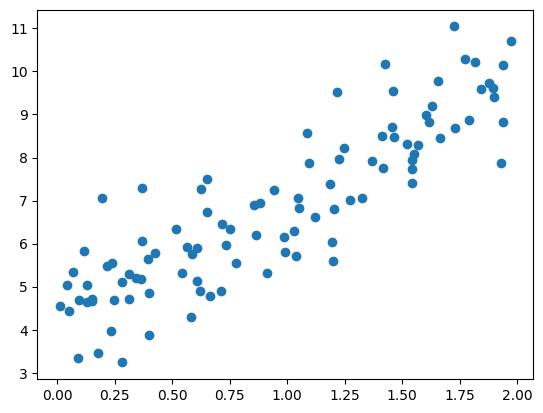

In [1]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42) # to make this code example reproducible
m = 100 # number of instances
X = 2 * np.random.rand(m, 1) # column vector
y = 4 + 3 * X + np.random.randn(m, 1) # column vector

plt.scatter(X,y)



In [2]:
from sklearn.preprocessing import add_dummy_feature
X_b = add_dummy_feature(X) # add x0 = 1 to each instance
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

In [3]:
theta_best

array([[4.21509616],
       [2.77011339]])

In [4]:
X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)
y_predict = X_new_b @ theta_best
y_predict

array([[4.21509616],
       [9.75532293]])

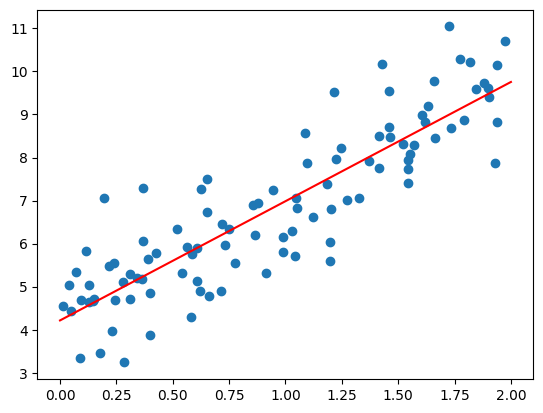

In [5]:
plt.plot(X_new, y_predict, 'r-', label='predictions')
plt.scatter(X, y)

In [6]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [7]:
lin_reg.intercept_ , lin_reg.coef_ # theta0, # theta1, theta2, theta3

(array([4.21509616]), array([[2.77011339]]))

In [8]:
theta_best_svd, residuals, rank, s = np.linalg.lstsq(
    X_b, y, rcond=1e-6
)
theta_best_svd, residuals, rank, s

(array([[4.21509616],
        [2.77011339]]),
 array([80.6584564]),
 np.int32(2),
 array([14.37020392,  4.11961067]))

In [9]:
np.linalg.pinv(X_b) @ y

array([[4.21509616],
       [2.77011339]])

In [10]:
eta = 0.001 # learning rate
n_epochs = 1000000
m = len(X_b) # number of instances

rng = np.random.default_rng(seed=42)

theta = rng.standard_normal((2, 1))

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

In [11]:
theta

array([[4.21509616],
       [2.77011339]])

In [12]:
n_epochs = 50
t0, t1 = 5, 50
# learning schedule hyperparameters
def learning_schedule(t):
    return t0 / (t + t1)
rng = np.random.default_rng(seed=42)
theta = rng.standard_normal((2, 1)) # randomly initialized model parameters

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = rng.integers(m)
        xi = X_b[random_index : random_index + 1]
        yi = y[random_index : random_index + 1]
        gradients = 2 * xi.T @ (xi @ theta - yi) # for SGD, do not divide by m
        eta = learning_schedule(epoch * m + iteration)
        theta = theta - eta * gradients

In [13]:
from sklearn.linear_model import SGDRegressor
sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0=0.01,
n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel()) # y.ravel() because fit() expects 1D targets

,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide `.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",1e-05
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [14]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.21278812]), array([2.77270267]))

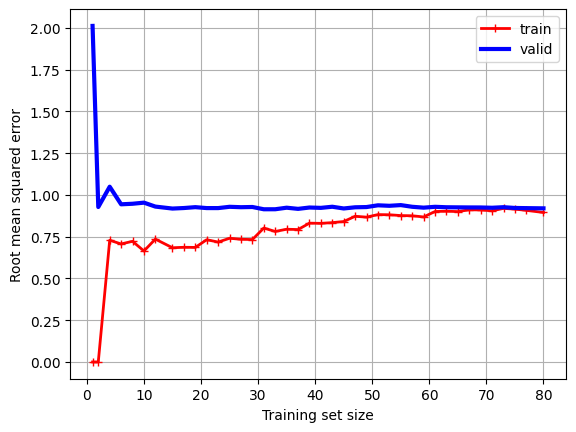

In [15]:
from sklearn.model_selection import learning_curve

learning_curve_result = learning_curve(
	LinearRegression(),
	X,
	y,
	train_sizes=np.linspace(0.01, 1.0, 40),
	cv=5,
	scoring="neg_root_mean_squared_error",
)
train_sizes = learning_curve_result[0]
train_scores = learning_curve_result[1]
valid_scores = learning_curve_result[2]

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)
plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
plt.xlabel("Training set size")
plt.ylabel("Root mean squared error")
plt.grid(True)
plt.legend()
plt.show()

In [16]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
polynomial_regression = make_pipeline(
    PolynomialFeatures(degree=10, include_bias=False),
    LinearRegression()
)

In [17]:
from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha=0.1)

ridge_reg.fit(X, y)

y_pred = ridge_reg.predict([[1.5]])
y_pred

array([8.36585531])

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

print(len(X))

X_train = X[:80]
y_train = y[:80]
X_test = X[80:]
y_test = y[80:]
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred

100


array([8.84101503, 7.56961531, 6.01936846, 4.60198698, 5.91377938,
       5.98907024, 8.13323933, 7.6452155 , 8.96883781, 6.76860239,
       4.89907809, 8.04649451, 8.29854346, 7.24079275, 8.35252709,
       6.88301879, 7.03643822, 6.53175028, 4.39978044, 4.83703208])

## Best alpha selection

In [19]:
from sklearn.linear_model import RidgeCV

ridge_cv = RidgeCV(
    alphas=[0.001, 0.01, 0.1, 1, 10, 100]
)

ridge_cv.fit(X_train, y_train)

print(ridge_cv.alpha_)

0.1


In [20]:
from sklearn.linear_model import Lasso

lasso_reg = Lasso(alpha=0.1)

lasso_reg.fit(X, y)

lasso_reg.predict([[1.5]])

array([8.2105793])

In [21]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5)

elastic_net.fit(X, y)

elastic_net.predict([[1.5]])

array([8.10683147])

In [22]:
from copy import deepcopy

from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import SGDRegressor


# Split the dataset into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# Preprocessing
preprocessing = make_pipeline(
    PolynomialFeatures(
        degree=90,
        include_bias=False
    ),
    StandardScaler()
)


# Prepare the training and validation data
X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)


# Create SGD Regressor
sgd_reg = SGDRegressor(
    penalty=None,
    eta0=0.002,
    random_state=42
)


# Early Stopping
n_epochs = 500
best_valid_rmse = float('inf')
best_model = None


for epoch in range(n_epochs):

    # Train for one epoch
    sgd_reg.partial_fit(
        X_train_prep,
        y_train
    )

    # Predict validation data
    y_valid_predict = sgd_reg.predict(
        X_valid_prep
    )

    # Calculate validation RMSE
    val_error = root_mean_squared_error(
        y_valid,
        y_valid_predict
    )

    # Save the best model
    if val_error < best_valid_rmse:

        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg)


# Display the best validation error
print("Best Validation RMSE:", best_valid_rmse)

# Display the best model
print("\nBest Model:")
print(best_model)

/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1352: DataConversionWar

Best Validation RMSE: 0.8314978158198528

Best Model:
SGDRegressor(eta0=0.002, penalty=None, random_state=42)


/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1352: DataConversionWar

In [23]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Load dataset
iris = load_iris(as_frame=True)

# Input feature
X = iris.data[["petal width (cm)"]].values

# Target: Virginica = 1, others = 0
y = (iris.target == 2).values

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    stratify=y
)

# Create and train model
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# Predict probabilities
probabilities = model.predict_proba(X_test)

# Predict classes
predictions = model.predict(X_test)

# Display results
print("First 5 probabilities:")
print(probabilities[:5])

print("First 5 predictions:")
print(predictions[:5])

print("Test accuracy:", model.score(X_test, y_test))

First 5 probabilities:
[[0.99628084 0.00371916]
 [0.92679596 0.07320404]
 [0.99628084 0.00371916]
 [0.98841067 0.01158933]
 [0.65270529 0.34729471]]
First 5 predictions:
[False False False False False]
Test accuracy: 0.9736842105263158


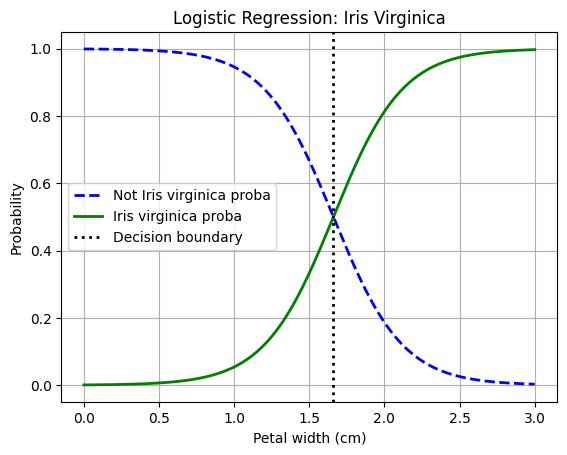

Decision boundary: 1.6607 cm


In [27]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

# Load the Iris dataset
iris = load_iris(as_frame=True)

# Use petal width as the feature
X = iris.data[["petal width (cm)"]].to_numpy()
y = (iris.target == 2).astype(int).to_numpy()

# Create and train the model
log_reg = LogisticRegression()
log_reg.fit(X, y)

# Generate new data
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)

# Predict probabilities
y_proba = log_reg.predict_proba(X_new)

# Find decision boundary (probability >= 0.5)
decision_boundary = X_new[
    y_proba[:, 1] >= 0.5
][0, 0]

# Plot probabilities
plt.plot(
    X_new[:, 0], y_proba[:, 0],
    "b--", linewidth=2,
    label="Not Iris virginica proba"
)

plt.plot(
    X_new[:, 0], y_proba[:, 1],
    "g-", linewidth=2,
    label="Iris virginica proba"
)

# Plot decision boundary
plt.axvline(
    decision_boundary,
    color="k", linestyle=":",
    linewidth=2,
    label="Decision boundary"
)

plt.xlabel("Petal width (cm)")
plt.ylabel("Probability")
plt.title("Logistic Regression: Iris Virginica")
plt.legend()
plt.grid(True)
plt.show()

print(f"Decision boundary: {decision_boundary:.4f} cm")


In [28]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
softmax_reg = LogisticRegression(C=30, random_state=42)
softmax_reg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",30
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multic

In [30]:
softmax_reg.predict([[5, 2]]), softmax_reg.predict_proba([[5, 2]]).round(2)

(array([2]), array([[0.  , 0.04, 0.96]]))

## Softmax Without Scikit-learn

Best validation loss: 0.11368523713777545
Test loss: 0.06081832082609178
Test accuracy: 1.0


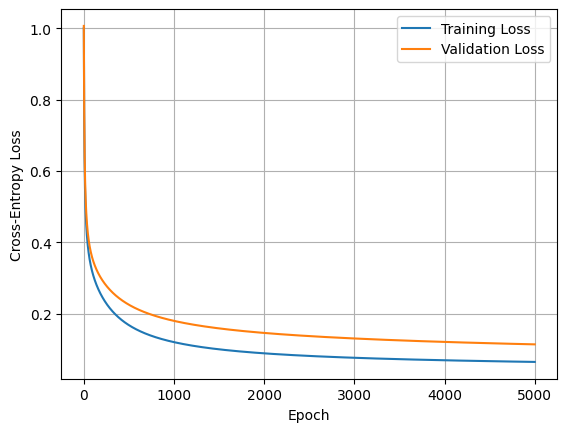

In [34]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Shuffle and split
np.random.seed(42)
indices = np.random.permutation(len(X))

train_idx = indices[:90]
val_idx = indices[90:120]
test_idx = indices[120:]

X_train, X_val, X_test = (
    X[train_idx], X[val_idx], X[test_idx]
)
y_train, y_val, y_test = (
    y[train_idx], y[val_idx], y[test_idx]
)

# Standardize using training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

# Add bias
X_train = np.c_[np.ones(len(X_train)), X_train]
X_val = np.c_[np.ones(len(X_val)), X_val]
X_test = np.c_[np.ones(len(X_test)), X_test]

# One-hot encoding
n_classes = 3
Y_train = np.eye(n_classes)[y_train]
Y_val = np.eye(n_classes)[y_val]

# Softmax
def softmax(logits):
    logits = logits - np.max(
        logits, axis=1, keepdims=True
    )
    exp_logits = np.exp(logits)
    return exp_logits / exp_logits.sum(
        axis=1, keepdims=True
    )

# Cross-entropy
def cross_entropy(X, Y, theta):
    probs = softmax(X @ theta)
    eps = 1e-15
    return -np.mean(
        np.sum(Y * np.log(probs + eps), axis=1)
    )

# Initialize parameters
theta = np.zeros((X_train.shape[1], n_classes))

learning_rate = 0.1
n_epochs = 5000
patience = 100
best_val_loss = float("inf")
best_theta = theta.copy()
wait = 0

train_losses = []
val_losses = []

# Batch Gradient Descent
for epoch in range(n_epochs):

    # Predict using current parameters
    probs = softmax(X_train @ theta)

    # Gradient
    gradient = (
        X_train.T @ (probs - Y_train)
    ) / len(X_train)

    # Update parameters
    theta -= learning_rate * gradient

    # Calculate losses after update
    train_loss = cross_entropy(
        X_train, Y_train, theta
    )
    val_loss = cross_entropy(
        X_val, Y_val, theta
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Early stopping based on validation loss
    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_theta = theta.copy()
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early stopping at epoch:", epoch + 1)
        break

# Restore best parameters
theta = best_theta

# Final test evaluation
Y_test = np.eye(n_classes)[y_test]
test_loss = cross_entropy(X_test, Y_test, theta)

y_pred = np.argmax(softmax(X_test @ theta), axis=1)
accuracy = np.mean(y_pred == y_test)

print("Best validation loss:", best_val_loss)
print("Test loss:", test_loss)
print("Test accuracy:", accuracy)

# Plot learning curves
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid()
plt.show()
